# Поиск статей справки Авито по обращениям пользователей

Тестовое задание. Есть 793 статьи справочного центра и обращения пользователей. Для каждого обращения нужно вернуть 10 самых релевантных статей; у части запросов правильных статей несколько. Метрика — MAP@10.

По сути это этап retrieval в RAG-ассистенте поддержки: найденные статьи потом передаются LLM, которая пишет ответ.

**Подход:**
1. Индекс из текста статей, дополненный размеченными обращениями: статья описывается и своим текстом, и тем, как о ней спрашивают пользователи.
2. BM25 и dense-поиск по эмбеддингам, затем их гибрид.
3. Реранкер на топ-50 гибрида и смесь гибрида с реранкером.

**Валидация:** калибровочная выборка делится пополам. Первая половина (tune) служит историей обращений для индекса и для подбора всех коэффициентов, на второй (holdout) честно измеряется качество. Итоговая таблица и разбор ошибок — в конце ноутбука.

Запуск: Kaggle, GPU T4 x2, интернет включён. Реранкер считает калибровку и тест параллельно на двух GPU, его скоры кэшируются. Данные в репозиторий не входят.

In [1]:
!pip install -q rank-bm25 pymorphy3 emoji langchain_text_splitters sentence-transformers beautifulsoup4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 589.8/589.8 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.1/135.1 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.6/69.6 kB 2.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.


In [2]:
import os
import re
import glob
import time
import pickle
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import emoji
import pymorphy3
from bs4 import BeautifulSoup
from rank_bm25 import BM25Okapi
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import SentenceTransformer, CrossEncoder

warnings.filterwarnings('ignore', module='bs4')

SEED = 42
N_GPU = torch.cuda.device_count()
DEVICE = 'cuda:0' if N_GPU else 'cpu'
print('GPU:', N_GPU)

GPU: 2


In [3]:
# ищем данные в подключённом датасете, где бы он ни лежал
path = os.path.dirname(glob.glob('/kaggle/input/**/articles.f', recursive=True)[0])
articles = pd.read_feather(os.path.join(path, 'articles.f'))
calibration = pd.read_feather(os.path.join(path, 'calibration.f')).reset_index(drop=True)
test_data = pd.read_feather(os.path.join(path, 'test.f'))

print(f'статей: {len(articles)}, калибровка: {len(calibration)}, тест: {len(test_data)}')

статей: 793, калибровка: 500, тест: 500


## Предобработка

Убираем HTML, эмодзи, плейсхолдеры анонимизации вроде `<MONEY>` и приветствие в начале обращения: «Здравствуйте» есть почти в каждом запросе и ничего не говорит о теме.

Некоторые статьи аномально длинные, самая длинная — полмиллиона символов. Обрезаем тело до 20 тысяч, чтобы одна статья не превращалась в сотни чанков.

In [4]:
def clean_text(text):
    text = BeautifulSoup(text, 'html.parser').get_text(' ', strip=True)
    text = emoji.replace_emoji(text, replace='')
    text = re.sub(r'<[A-Z_]+>', ' ', text)  # <MONEY>, <ID> и т.п.
    text = re.sub(r'^(здравствуйте|добрый день|привет|доброе утро|добрый вечер)[!,.\s]*', '',
                  text, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', text).strip()


LIMIT = 20_000

articles['title_clean'] = articles.title.apply(clean_text)
articles['body_clean'] = articles.body.apply(clean_text)
print('длина тела до обрезки:')
print(articles.body_clean.str.len().describe().round())
print(f'статей длиннее {LIMIT}: {(articles.body_clean.str.len() > LIMIT).sum()}')
articles['body_clean'] = articles.body_clean.str.slice(0, LIMIT)

calibration['text'] = calibration.query_text.apply(clean_text)
test_data['text'] = test_data.query_text.apply(clean_text)

GT = calibration.ground_truth.apply(lambda s: list(map(int, s.split()))).tolist()
TITLE = articles.set_index('article_id').title_clean.to_dict()

длина тела до обрезки:
count       793.0
mean       5129.0
std       19115.0
min          24.0
25%        1157.0
50%        2240.0
75%        4752.0
max      506100.0
Name: body_clean, dtype: float64
статей длиннее 20000: 31


## Разбиение калибровки

Половина запросов (tune) — для подбора параметров и как история обращений, вторая половина (holdout) — только для итоговой оценки. Если подбирать параметры и мерить качество на одних и тех же запросах, метрика получается завышенной.

In [5]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(calibration))
TUNE = np.sort(perm[:len(perm) // 2])
HOLD = np.sort(perm[len(perm) // 2:])
CAL_IDS = np.arange(len(calibration))
print(f'tune: {len(TUNE)} запросов, holdout: {len(HOLD)}')

tune: 250 запросов, holdout: 250


## Метрики

MAP@10 — метрика задания: учитывает, насколько высоко стоят правильные статьи. Recall@k показывает, какая доля правильных статей вообще попала в топ-k. Recall@50 важен для реранкера: он переставляет только топ-50 гибрида.

In [6]:
def ranking(pred):
    return sorted(pred, key=pred.get, reverse=True)


def ap_at_k(ranked, gt, k=10):
    hits, score = 0, 0.0
    for i, aid in enumerate(ranked[:k], start=1):
        if aid in gt:
            hits += 1
            score += hits / i
    return score / min(len(gt), k)


def evaluate(preds, idx):
    ranked = [ranking(preds[i]) for i in idx]
    gts = [GT[i] for i in idx]
    return {
        'MAP@10': np.mean([ap_at_k(r, g) for r, g in zip(ranked, gts)]),
        'Recall@10': np.mean([len(set(r[:10]) & set(g)) / len(g) for r, g in zip(ranked, gts)]),
        'Recall@50': np.mean([len(set(r[:50]) & set(g)) / len(g) for r, g in zip(ranked, gts)]),
    }


def show(name, preds):
    t, h = evaluate(preds, TUNE), evaluate(preds, HOLD)
    print(f"{name:<32} MAP@10 tune {t['MAP@10']:.4f} | holdout {h['MAP@10']:.4f}"
          f" | Recall@10 {h['Recall@10']:.4f} | Recall@50 {h['Recall@50']:.4f}")

## История обращений

Из разбора ошибок прошлой версии: чаще всего поиск проваливается на эмоциональных жалобах («почему доставка такая дорогая?», «носки стоят дешевле доставки»). Статья о стоимости доставки написана справочным языком, и с жалобой у неё не совпадают ни слова, ни формулировки.

Можно было бы написать правило под доставку, но это подгонка под конкретные ошибки, и оно не поможет с другими темами. Вместо этого используется общий приём из поиска по поддержке: к каждой статье добавляются размеченные обращения, которые к ней относятся. Статья становится находимой и по своему тексту, и по тому, как о ней спрашивают люди. В продакшене такую историю дают логи поддержки: какую статью оператор отправил в ответ на обращение.

Обращения добавляются в индекс как дополнительные «чанки» статьи, поэтому выигрыш получают и BM25, и dense-поиск, и реранкер.

Чтобы не было утечки:
- для оценки на калибровке в индекс попадают только обращения из tune, holdout остаётся невидимым;
- запрос из tune не может найти сам себя: его собственная запись исключается при поиске (leave-one-out);
- для теста историей служит вся калибровка.

In [7]:
def make_memory(idx):
    # одна запись на пару «обращение — правильная статья»
    rows = [{'article_id': aid, 'text': calibration.text[i], 'src': i} for i in idx for aid in GT[i]]
    return pd.DataFrame(rows, columns=['article_id', 'text', 'src']).astype({'article_id': int, 'src': int})


memory_tune = make_memory(TUNE)       # для оценки на калибровке
memory_all = make_memory(CAL_IDS)     # для теста

covered = memory_tune.article_id.nunique()
print(f'записей в истории tune: {len(memory_tune)}, статей с историей: {covered} из {len(articles)}')

записей в истории tune: 386, статей с историей: 61 из 793


## Чанки

Статьи режутся на чанки с перекрытием 10%, в начало каждого чанка добавляется заголовок статьи: иначе кусок из середины теряет контекст.

Размер свой для каждого поиска: для BM25 короткие чанки по 1000 символов, где совпадение слов точнее указывает на нужный фрагмент, для эмбеддингов — по 4000, чтобы модель видела больше контекста. Для BM25 слова лемматизируются через pymorphy3: в русском одно слово встречается во множестве форм.

In [8]:
def make_chunks(articles, size):
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=int(size * 0.1),
                                              separators=['. ', '! ', '? ', ' ', ''])
    rows = []
    for _, row in articles.iterrows():
        for chunk in splitter.split_text(row.body_clean):
            rows.append({'article_id': row.article_id, 'text': f'{row.title_clean}. {chunk}', 'src': -1})
    print(f'{len(rows)} чанков по {size} символов')
    return pd.DataFrame(rows)


morph = pymorphy3.MorphAnalyzer()


@lru_cache(maxsize=500_000)
def lemmatize(word):
    return morph.parse(word)[0].normal_form


def tokenize(text):
    return [lemmatize(w) for w in re.sub(r'[^\w\s]', ' ', text).lower().split()]


chunks_bm25 = make_chunks(articles, 1000)
chunks_dense = make_chunks(articles, 4000)

4025 чанков по 1000 символов
1312 чанков по 4000 символов


## Два поиска

Оба поиска оценивают чанки, а скор статьи — лучший скор среди её чанков, включая записи истории.

- **BM25** ловит точные совпадения слов: названия сервисов, «тариф», «доставка».
- **Dense-поиск** ловит смысл, когда пользователь пишет своими словами. Модель — [deepvk/USER-bge-m3](https://huggingface.co/deepvk/USER-bge-m3), мультиязычная bge-m3, дообученная на русском: и запросы, и статьи русские.

Чанков около полутора тысяч, поэтому dense-поиск точный: одно матричное умножение нормированных векторов. На миллионах документов здесь понадобился бы приближённый поиск, например FAISS.

Насколько доверять истории, решают данные: скоры записей истории умножаются на вес alpha, который подбирается на tune отдельно для каждого поиска. При alpha = 0 история не используется, так что, если она вредит (например, из-за шумной разметки), подбор сам откатит поиск к индексу только из статей. Строки «без истории» в таблицах — это alpha = 0.

In [9]:
ALPHAS = [0, 0.25, 0.5, 0.75, 1.0]


def aggregate(chunk_scores, aids, src, alpha, query_ids=None):
    # chunk_scores: запросы × чанки; alpha — вес записей истории;
    # query_ids — номер запроса в калибровке, чтобы он не нашёл сам себя
    hist = src >= 0
    results = []
    for qi, row in enumerate(chunk_scores):
        row = np.where(hist, -np.inf if alpha == 0 else alpha * row, row)
        if query_ids is not None:
            row = np.where(src == query_ids[qi], -np.inf, row)
        scores = pd.Series(row).groupby(aids).max()
        results.append(scores.sort_values(ascending=False).to_dict())
    return results


def tune_alpha(chunk_scores, aids, src):
    maps = {a: evaluate(aggregate(chunk_scores, aids, src, a, CAL_IDS), TUNE)['MAP@10'] for a in ALPHAS}
    print('  MAP@10 на tune по alpha:', {a: round(float(m), 4) for a, m in maps.items()})
    return max(maps, key=maps.get)


TOKENS = {}


def cached_tokens(text):
    if text not in TOKENS:
        TOKENS[text] = tokenize(text)
    return TOKENS[text]


def bm25_scores(memory, queries):
    chunks = pd.concat([chunks_bm25, memory], ignore_index=True)
    model = BM25Okapi([cached_tokens(t) for t in chunks.text])
    scores = np.array([model.get_scores(cached_tokens(q)) for q in queries])
    return scores, chunks.article_id.values, chunks.src.values


t = time.time()
bm25_raw_cal = bm25_scores(memory_tune, calibration.text)
bm25_raw_test = bm25_scores(memory_all, test_data.text)
print(f'BM25: {time.time() - t:.0f} с')

ALPHA_BM25 = tune_alpha(*bm25_raw_cal)
bm25_base = aggregate(*bm25_raw_cal, 0, CAL_IDS)
bm25_cal = aggregate(*bm25_raw_cal, ALPHA_BM25, CAL_IDS)
bm25_test = aggregate(*bm25_raw_test, ALPHA_BM25)
print(f'вес истории для BM25: {ALPHA_BM25}')
show('BM25', bm25_base)
show('BM25 + история', bm25_cal)

BM25: 12 с
  MAP@10 на tune по alpha: {0: 0.3197, 0.25: 0.3197, 0.5: 0.3241, 0.75: 0.3628, 1.0: 0.4043}
вес истории для BM25: 1.0
BM25                             MAP@10 tune 0.3197 | holdout 0.2943 | Recall@10 0.5940 | Recall@50 0.9073
BM25 + история                   MAP@10 tune 0.4043 | holdout 0.4020 | Recall@10 0.7280 | Recall@50 0.9467


In [10]:
encoder = SentenceTransformer('deepvk/USER-bge-m3', device=DEVICE)


def encode(texts):
    return encoder.encode(list(texts), batch_size=32, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False)


t = time.time()
art_emb = encode(chunks_dense.text)
cal_emb = encode(calibration.text)
test_emb = encode(test_data.text)
print(f'эмбеддинги: {time.time() - t:.0f} с')

# энкодер больше не нужен, освобождаем видеопамять под реранкер
del encoder
torch.cuda.empty_cache()


def dense_scores(memory, query_emb):
    # эмбеддинги обращений истории уже посчитаны: это строки cal_emb
    emb = np.vstack([art_emb, cal_emb[memory.src.values]])
    aids = np.concatenate([chunks_dense.article_id.values, memory.article_id.values])
    src = np.concatenate([chunks_dense.src.values, memory.src.values])
    return query_emb @ emb.T, aids, src  # косинусная близость


dense_raw_cal = dense_scores(memory_tune, cal_emb)
dense_raw_test = dense_scores(memory_all, test_emb)

ALPHA_DENSE = tune_alpha(*dense_raw_cal)
dense_base = aggregate(*dense_raw_cal, 0, CAL_IDS)
dense_cal = aggregate(*dense_raw_cal, ALPHA_DENSE, CAL_IDS)
dense_test = aggregate(*dense_raw_test, ALPHA_DENSE)
print(f'вес истории для dense: {ALPHA_DENSE}')
show('Dense', dense_base)
show('Dense + история', dense_cal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/697 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.44G [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/963 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

эмбеддинги: 215 с
  MAP@10 на tune по alpha: {0: 0.4292, 0.25: 0.4292, 0.5: 0.4292, 0.75: 0.5001, 1.0: 0.5442}
вес истории для dense: 1.0
Dense                            MAP@10 tune 0.4292 | holdout 0.4375 | Recall@10 0.7683 | Recall@50 0.9687
Dense + история                  MAP@10 tune 0.5442 | holdout 0.5746 | Recall@10 0.8740 | Recall@50 0.9847


## Гибридный поиск

Поиски ошибаются на разных запросах, поэтому их стоит объединить. Сравниваю два способа:

- **взвешенная сумма скоров:** BM25 нормируется на максимум по запросу, вес dense подбирается;
- **Reciprocal Rank Fusion:** складываются 1/(k + позиция) из обоих списков, сами скоры не нужны, подбирается k.

Параметры подбираются только на tune. График показывает, сколько стоит подбор на тех же данных: кривая tune обычно идёт выше holdout.

In [11]:
def hybrid_weighted(bm_preds, dn_preds, coef):
    results = []
    for b, d in zip(bm_preds, dn_preds):
        b_max = max(b.values()) if b and max(b.values()) > 0 else 1
        scores = {aid: coef * d.get(aid, 0) + (1 - coef) * b.get(aid, 0) / b_max for aid in set(b) | set(d)}
        results.append(dict(sorted(scores.items(), key=lambda x: -x[1])))
    return results


def rrf(rankings_list, weights, k):
    scores = {}
    for ranked, w in zip(rankings_list, weights):
        for pos, aid in enumerate(ranked, start=1):
            scores[aid] = scores.get(aid, 0) + w / (k + pos)
    return dict(sorted(scores.items(), key=lambda x: -x[1]))


def hybrid_rrf(bm_preds, dn_preds, k):
    return [rrf([ranking(b), ranking(d)], [1, 1], k) for b, d in zip(bm_preds, dn_preds)]


def map_subset(make_preds, bm, dn, idx):
    # считаем предсказания только для нужных запросов и сравниваем с их разметкой
    preds = make_preds([bm[i] for i in idx], [dn[i] for i in idx])
    return np.mean([ap_at_k(ranking(p), GT[i]) for p, i in zip(preds, idx)])

вес dense без истории: 0.88, с историей: 0.76; лучший k для RRF: 20


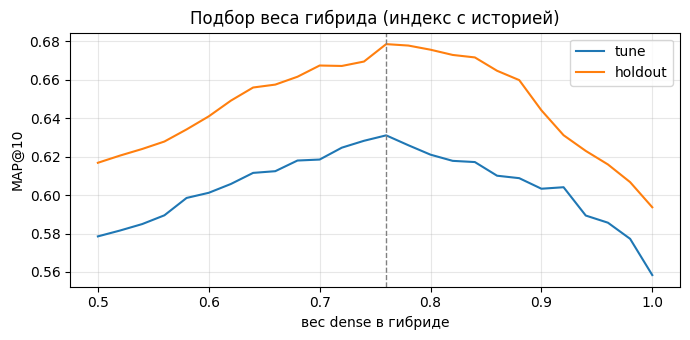

In [12]:
COEFS = np.round(np.arange(0.5, 1.001, 0.02), 2)


def tune_coef(bm, dn):
    curve = [map_subset(lambda b, d: hybrid_weighted(b, d, c), bm, dn, TUNE) for c in COEFS]
    return COEFS[int(np.argmax(curve))], curve


BASE_COEF, _ = tune_coef(bm25_base, dense_base)
BEST_COEF, curve_tune = tune_coef(bm25_cal, dense_cal)
curve_hold = [map_subset(lambda b, d: hybrid_weighted(b, d, c), bm25_cal, dense_cal, HOLD) for c in COEFS]

RRF_KS = [5, 10, 20, 30, 60]
rrf_tune = [map_subset(lambda b, d: hybrid_rrf(b, d, k), bm25_cal, dense_cal, TUNE) for k in RRF_KS]
BEST_RRF_K = RRF_KS[int(np.argmax(rrf_tune))]

print(f'вес dense без истории: {BASE_COEF}, с историей: {BEST_COEF}; лучший k для RRF: {BEST_RRF_K}')

plt.figure(figsize=(7, 3.5))
plt.plot(COEFS, curve_tune, label='tune')
plt.plot(COEFS, curve_hold, label='holdout')
plt.axvline(BEST_COEF, color='grey', ls='--', lw=1)
plt.xlabel('вес dense в гибриде')
plt.ylabel('MAP@10')
plt.title('Подбор веса гибрида (индекс с историей)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
hyb_base_cal = hybrid_weighted(bm25_base, dense_base, BASE_COEF)
hyb_w_cal = hybrid_weighted(bm25_cal, dense_cal, BEST_COEF)
hyb_r_cal = hybrid_rrf(bm25_cal, dense_cal, BEST_RRF_K)
show('Гибрид без истории', hyb_base_cal)
show('Гибрид + история, взвешенная', hyb_w_cal)
show('Гибрид + история, RRF', hyb_r_cal)

# дальше идёт тот способ, что лучше на tune
use_weighted = evaluate(hyb_w_cal, TUNE)['MAP@10'] >= evaluate(hyb_r_cal, TUNE)['MAP@10']
HYBRID_NAME = 'взвешенная сумма' if use_weighted else 'RRF'
if use_weighted:
    hybrid_cal, hybrid_test = hyb_w_cal, hybrid_weighted(bm25_test, dense_test, BEST_COEF)
else:
    hybrid_cal, hybrid_test = hyb_r_cal, hybrid_rrf(bm25_test, dense_test, BEST_RRF_K)
print('дальше используется гибрид:', HYBRID_NAME)

Гибрид без истории               MAP@10 tune 0.4982 | holdout 0.5155 | Recall@10 0.8473 | Recall@50 0.9760
Гибрид + история, взвешенная     MAP@10 tune 0.6311 | holdout 0.6785 | Recall@10 0.9293 | Recall@50 0.9940
Гибрид + история, RRF            MAP@10 tune 0.5847 | holdout 0.6041 | Recall@10 0.9200 | Recall@50 0.9940
дальше используется гибрид: взвешенная сумма


## Реранкер

Cross-encoder [BAAI/bge-reranker-v2-m3](https://huggingface.co/BAAI/bge-reranker-v2-m3) читает запрос и текст вместе, поэтому точнее эмбеддингов, но намного медленнее. Он оценивает статьи из топ-50 гибрида: все их чанки и записи истории. Скор статьи — максимум. История помогает и здесь: жалобу «почему так дорого» реранкеру проще сопоставить с похожей прошлой жалобой, чем с текстом справки. Правило leave-one-out действует и тут, а вес записей истории для реранкера тоже подбирается на tune.

Ускорения:
- пары сортируются по длине, чтобы в батче было меньше паддинга;
- калибровка и тест считаются одновременно, каждый на своей GPU;
- результат кэшируется на диск, повторный запуск ноутбука не пересчитывает реранкер.

In [14]:
TOP_K = 50


def texts_by_article(memory):
    # статья -> список (текст, номер обращения-источника); у чанков статьи источник -1
    rows = pd.concat([chunks_dense, memory], ignore_index=True)
    return {aid: list(zip(g.text, g.src)) for aid, g in rows.groupby('article_id')}


def load_reranker(device):
    model = CrossEncoder('BAAI/bge-reranker-v2-m3', max_length=1024, device=device,
                         trust_remote_code=True)
    if device != 'cpu':
        model.model.half()
    return model


def rerank_aggregate(raw, alpha):
    # скор статьи — максимум по её чанкам и записям истории (с весом alpha)
    results = []
    for items in raw:
        scores = {}
        for aid, is_hist, s in items:
            if is_hist:
                if alpha == 0:
                    continue
                s = alpha * s
            scores[aid] = max(scores.get(aid, -np.inf), s)
        results.append(dict(sorted(scores.items(), key=lambda x: -x[1])))
    return results


def rerank(model, queries, hybrid_preds, texts, query_ids, cache_path):
    if os.path.exists(cache_path):
        with open(cache_path, 'rb') as f:
            return pickle.load(f)

    pairs, owners = [], []
    for qi, (query, pred) in enumerate(zip(queries, hybrid_preds)):
        for aid in ranking(pred)[:TOP_K]:
            for text, src in texts[aid]:
                if query_ids is not None and src == query_ids[qi]:
                    continue  # запрос не сравнивается сам с собой
                pairs.append((query, text))
                owners.append((qi, aid, src >= 0))

    t = time.time()
    order = np.argsort([len(q) + len(c) for q, c in pairs])
    sorted_scores = model.predict([pairs[i] for i in order], batch_size=16, show_progress_bar=False)
    scores = np.empty(len(pairs))
    scores[order] = sorted_scores
    print(f'{cache_path}: {len(pairs)} пар, {(time.time() - t) / 60:.1f} мин')

    # храним скоры пар, а не статей: так вес истории можно подбирать без пересчёта
    results = [[] for _ in queries]
    for (qi, aid, is_hist), s in zip(owners, scores):
        results[qi].append((aid, is_hist, float(s)))
    with open(cache_path, 'wb') as f:
        pickle.dump(results, f)
    return results

In [15]:
jobs = [(list(calibration.text), hybrid_cal, texts_by_article(memory_tune), CAL_IDS, 'rerank_cal_v3.pkl'),
        (list(test_data.text), hybrid_test, texts_by_article(memory_all), None, 'rerank_test_v3.pkl')]

if N_GPU >= 2:
    rerankers = [load_reranker('cuda:0'), load_reranker('cuda:1')]
    with ThreadPoolExecutor(max_workers=2) as pool:
        futures = [pool.submit(rerank, m, *job) for m, job in zip(rerankers, jobs)]
        raw_cal, raw_test = [f.result() for f in futures]
else:
    reranker = load_reranker(DEVICE)
    raw_cal, raw_test = [rerank(reranker, *job) for job in jobs]

# реранкер выдаёт логиты или вероятности, поэтому вес истории применяем к скору
# после сдвига в положительную область: так alpha < 1 всегда понижает запись истории
shift = min(s for items in raw_cal + raw_test for _, _, s in items)
raw_cal = [[(a, h, s - shift) for a, h, s in items] for items in raw_cal]
raw_test = [[(a, h, s - shift) for a, h, s in items] for items in raw_test]

rerank_maps = {a: evaluate(rerank_aggregate(raw_cal, a), TUNE)['MAP@10'] for a in ALPHAS}
print('  MAP@10 на tune по alpha:', {a: round(float(m), 4) for a, m in rerank_maps.items()})
ALPHA_RERANK = max(rerank_maps, key=rerank_maps.get)
print(f'вес истории для реранкера: {ALPHA_RERANK}')

rerank_cal = rerank_aggregate(raw_cal, ALPHA_RERANK)
rerank_test = rerank_aggregate(raw_test, ALPHA_RERANK)
show('Гибрид + реранкер', rerank_cal)

config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.27G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

rerank_cal_v3.pkl: 214617 пар, 50.0 мин
rerank_test_v3.pkl: 372458 пар, 53.6 мин
  MAP@10 на tune по alpha: {0: 0.4995, 0.25: 0.5362, 0.5: 0.5578, 0.75: 0.582, 1.0: 0.6311}
вес истории для реранкера: 1.0
Гибрид + реранкер                MAP@10 tune 0.6311 | holdout 0.6557 | Recall@10 0.9367 | Recall@50 0.9940


In [16]:
print('  MAP@10 на tune по alpha:', {a: round(float(m), 4) for a, m in rerank_maps.items()})
print(f'вес истории для реранкера: {ALPHA_RERANK}')
show('Гибрид + реранкер', rerank_cal)

  MAP@10 на tune по alpha: {0: 0.4995, 0.25: 0.5362, 0.5: 0.5578, 0.75: 0.582, 1.0: 0.6311}
вес истории для реранкера: 1.0
Гибрид + реранкер                MAP@10 tune 0.6311 | holdout 0.6557 | Recall@10 0.9367 | Recall@50 0.9940


## Смесь гибрида и реранкера

Реранкер и гибрид опираются на разные сигналы: у гибрида есть точные совпадения слов из BM25, а реранкер видит только начало длинного чанка (до 1024 токенов). Поэтому их ранжирования смешиваются через RRF; вес реранкера и k подбираются на tune. Вес 0 тоже в сетке: если реранкер не помогает, финалом останется гибрид.

In [17]:
def blend(hybrid_preds, rerank_preds, w, k):
    return [rrf([ranking(r), ranking(h)], [w, 1], k) for h, r in zip(hybrid_preds, rerank_preds)]


def blend_map(idx, w, k):
    preds = blend([hybrid_cal[i] for i in idx], [rerank_cal[i] for i in idx], w, k)
    return np.mean([ap_at_k(ranking(p), GT[i]) for p, i in zip(preds, idx)])


# w = 0 — чистый гибрид: если реранкер не помогает, подбор это покажет
grid = [(w, k) for w in np.round(np.arange(0, 2.01, 0.1), 1) for k in [10, 20, 30, 60]]
grid_scores = [blend_map(TUNE, w, k) for w, k in grid]
BEST_W, BEST_K = grid[int(np.argmax(grid_scores))]
print(f'лучшие на tune: вес реранкера {BEST_W}, k = {BEST_K}')

blend_cal = blend(hybrid_cal, rerank_cal, BEST_W, BEST_K)
show('Гибрид + реранкер, смесь', blend_cal)

лучшие на tune: вес реранкера 1.0, k = 60
Гибрид + реранкер, смесь         MAP@10 tune 0.7077 | holdout 0.7074 | Recall@10 0.9660 | Recall@50 0.9940


## Итоги на holdout

Все параметры подобраны на tune, история обращений тоже взята из tune. Здесь — качество на запросах, которые нигде не участвовали. В holdout около 250 запросов, поэтому разница меньше примерно 0.02 между соседними строками — на уровне шума.

,MAP@10 tune,MAP@10,Recall@10,Recall@50
Этап,,,,
BM25,0.320,0.294,0.594,0.907
BM25 + история (alpha 1.0),0.404,0.402,0.728,0.947
Dense (USER-bge-m3),0.429,0.438,0.768,0.969
Dense + история (alpha 1.0),0.544,0.575,0.874,0.985
Гибрид без истории (вес dense 0.88),0.498,0.516,0.847,0.976
"Гибрид + история, взвешенная сумма (вес dense 0.76)",0.631,0.679,0.929,0.994
"Гибрид + история, RRF (k = 20)",0.585,0.604,0.920,0.994
Гибрид + история (взвешенная сумма) + реранкер (alpha 1.0),0.631,0.656,0.937,0.994
"Гибрид + реранкер, смесь через RRF",0.708,0.707,0.966,0.994


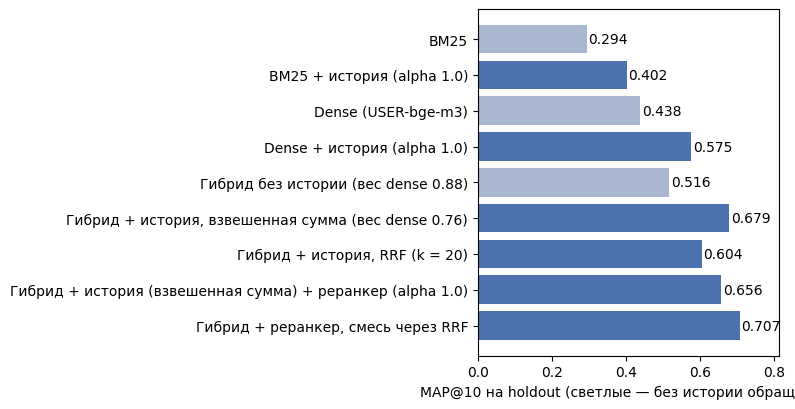

In [18]:
stages = {
    'BM25': bm25_base,
    f'BM25 + история (alpha {ALPHA_BM25})': bm25_cal,
    'Dense (USER-bge-m3)': dense_base,
    f'Dense + история (alpha {ALPHA_DENSE})': dense_cal,
    f'Гибрид без истории (вес dense {BASE_COEF})': hyb_base_cal,
    f'Гибрид + история, взвешенная сумма (вес dense {BEST_COEF})': hyb_w_cal,
    f'Гибрид + история, RRF (k = {BEST_RRF_K})': hyb_r_cal,
    f'Гибрид + история ({HYBRID_NAME}) + реранкер (alpha {ALPHA_RERANK})': rerank_cal,
    'Гибрид + реранкер, смесь через RRF': blend_cal,
}
rows = []
for name, preds in stages.items():
    h = evaluate(preds, HOLD)
    rows.append({'Этап': name, 'MAP@10 tune': evaluate(preds, TUNE)['MAP@10'], **h})
results = pd.DataFrame(rows).set_index('Этап').round(3)
display(results)

plt.figure(figsize=(8, 4.2))
colors = ['#4C72B0' if 'история' in n or 'смесь' in n or 'реранкер' in n else '#A9B8D0' for n in results.index]
plt.barh(results.index[::-1], results['MAP@10'][::-1], color=colors[::-1])
for y, v in enumerate(results['MAP@10'][::-1]):
    plt.text(v + 0.005, y, f'{v:.3f}', va='center')
plt.xlabel('MAP@10 на holdout (светлые — без истории обращений)')
plt.xlim(0, results['MAP@10'].max() * 1.15)
plt.tight_layout()
plt.show()

## Разбор ошибок

Смотрю запросы из holdout, на которых финальный пайплайн не нашёл ни одной правильной статьи в топ-10. Важно понять, где статья теряется:

- у правильной статьи нет ни одного обращения в истории — история здесь помочь не могла;
- правильная статья была в топ-50 гибрида — реранкер её видел, но не поднял;
- правильная статья дальше 50-го места — до реранкера она не дошла.

In [19]:
def position(pred, aid):
    ranked = ranking(pred)
    return ranked.index(aid) + 1 if aid in ranked else None


with_history = set(memory_tune.article_id)
ap_hold = {i: ap_at_k(ranking(blend_cal[i]), GT[i]) for i in HOLD}
fails = [i for i in HOLD if ap_hold[i] == 0]
no_hist = [i for i in fails if not set(GT[i]) & with_history]
in_top50 = [i for i in fails if any((position(hybrid_cal[i], a) or 10**9) <= TOP_K for a in GT[i])]

print(f'провалов (AP@10 = 0): {len(fails)} из {len(HOLD)}')
print(f'  у правильной статьи нет истории обращений: {len(no_hist)}')
print(f'  правильная статья была в топ-{TOP_K} гибрида: {len(in_top50)}')
print(f'  правильная статья дальше топ-{TOP_K}: {len(fails) - len(in_top50)}')

print()
print('Какие статьи чаще всего не находятся:')
for aid, n in Counter(a for i in fails for a in GT[i]).most_common(5):
    print(f'  {n:>3}  {TITLE.get(aid, aid)}  (обращений в истории: {(memory_tune.article_id == aid).sum()})')

# как изменились запросы о стоимости доставки — главный источник провалов прошлой версии
delivery = [i for i in HOLD if re.search(r'доставк', calibration.text[i], re.I)
            and re.search(r'дорог|цен|стои|сумм', calibration.text[i], re.I)]
if delivery:
    before = np.mean([ap_at_k(ranking(hyb_base_cal[i]), GT[i]) for i in delivery])
    after = np.mean([ap_at_k(ranking(blend_cal[i]), GT[i]) for i in delivery])
    print(f'\nзапросы о цене доставки в holdout: {len(delivery)}, '
          f'MAP@10 гибрида без истории {before:.3f} -> финал {after:.3f}')

провалов (AP@10 = 0): 4 из 250
  у правильной статьи нет истории обращений: 4
  правильная статья была в топ-50 гибрида: 3
  правильная статья дальше топ-50: 1

Какие статьи чаще всего не находятся:
    2  Ошибка при подаче объявления через приложение  (обращений в истории: 0)
    1  Не могу вывести деньги за доставку  (обращений в истории: 0)
    1  Отзыв отклонили  (обращений в истории: 0)

запросы о цене доставки в holdout: 38, MAP@10 гибрида без истории 0.317 -> финал 0.840


In [20]:
for i in fails[:12]:
    print(f'запрос: {calibration.query_text[i][:120]}')
    for aid in GT[i]:
        print(f'  нужно: {TITLE.get(aid, aid)!r} — место в гибриде {position(hybrid_cal[i], aid)},'
              f' в финале {position(blend_cal[i], aid)}')
    print(f'  нашли: {[TITLE.get(a, a) for a in ranking(blend_cal[i])[:3]]}')
    print()

запрос: Добрый день, подскажите не получается оплатить объявление и выставить его
  нужно: 'Ошибка при подаче объявления через приложение' — место в гибриде 171, в финале 171
  нашли: ['Бонусы', 'Платёж не прошёл', 'Не получается опубликовать объявление']

запрос: здравствуйте ! не могу разместить объявление ? выдает что ошибка
  нужно: 'Ошибка при подаче объявления через приложение' — место в гибриде 18, в финале 11
  нашли: ['Не получается опубликовать объявление', 'Ошибки при автозагрузке', 'Не получается опубликовать объявление о недвижимости']

запрос: Добрый день. Подскажите пожалуйста, а где мои 10тысяч которые я вывел на т-банк себе?
  нужно: 'Не могу вывести деньги за доставку' — место в гибриде 26, в финале 32
  нашли: ['Когда вернутся деньги после отмены доставки в пункт выдачи', 'Баланс для покупок', 'Покупателю']

запрос: О каких накрутках речь, я заказал духи в другом городе, авито доставкой?!
  нужно: 'Отзыв отклонили' — место в гибриде 47, в финале 14
  нашли: ['Скидки,

**Выводы**

- История обращений должна закрывать разрыв между языком пользователя и языком справки: новая жалоба находит похожую прошлую жалобу, а через неё — нужную статью. Насколько это сработало, видно по парам строк «без истории» и «с историей» в таблице, по подобранным весам alpha и по отдельной строке для запросов о цене доставки. Если alpha = 0, подбор решил, что история не помогает этому поиску.
- Ограничение приёма: он не помогает статьям, о которых ещё не спрашивали, и переносит ошибки разметки. В продакшене историю дают логи поддержки, и её нужно регулярно обновлять.

Что попробовать дальше:

1. Переписывать запрос через LLM перед поиском: из жалобы получать нейтральный вопрос в терминах справки. Это поможет и статьям без истории.
2. Дообучить реранкер на парах «запрос — статья» из истории.
3. Подбирать параметры кросс-валидацией по нескольким разбиениям: holdout в 250 запросов даёт шумную оценку.

## Предсказание на тесте

Тот же пайплайн с параметрами, подобранными на tune. Историей обращений для теста служит вся калибровка — вдвое больше, чем при валидации, поэтому на тесте качество ожидается не ниже, чем на holdout.

In [21]:
test_blend = blend(hybrid_test, rerank_test, BEST_W, BEST_K)

answer = test_data[['query_id']].copy()
answer['answer'] = [' '.join(map(str, ranking(p)[:10])) for p in test_blend]
answer.to_csv('answer.csv', index=False)

# проверки формата перед отправкой
check = pd.read_csv('answer.csv')
valid_ids = set(articles.article_id)
assert list(check.columns) == ['query_id', 'answer']
assert set(check.query_id) == set(test_data.query_id) and len(check) == len(test_data)
for ans in check.answer:
    ids = list(map(int, ans.split()))
    assert 0 < len(ids) <= 10
    assert len(ids) == len(set(ids))
    assert set(ids) <= valid_ids
print(f'OK: {len(check)} запросов, answer.csv готов')
check.head()

OK: 500 запросов, answer.csv готов


,query_id,answer
0,1,4308 4396 4384 4219 4234 2646 4214 3565 4328 1909
1,2,4219 2646 4407 4361 4403 1923 4408 2802 4234 4400
2,3,1909 4234 4396 4308 4328 4400 4219 4286 1907 2646
3,4,4234 4400 4532 2646 4219 2865 4361 4408 4331 1951
4,5,1951 4214 3467 4219 4286 4308 2698 4396 4328 4234
